# 5.3 Slender braced column: nominal curvature method

A stand-alone double-height entrance column. Second-order effects are calculated with EC2 5.8.8.

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

## Method (EC2 5.8.8)

$$M_2=N_{Ed}e_2,\quad e_2=\frac1r\frac{l_0^2}{c},\quad \frac1r=K_rK_\varphi\frac{\varepsilon_{yd}}{0.45d},\quad K_r=\frac{n_u-n}{n_u-n_{bal}}\le1,\quad K_\varphi=1+\beta\varphi_{ef}\ge1$$

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `N` | Design axial load (ULS) | kN | > 0 |
| `Mt`, `Mb` | Design end moments, top and bottom (ULS) | kN·m | same sign = tension on the same side |
| `b`, `h` | Section; h in the plane of bending | mm | > 0 |
| `l` | Clear height | m | > 0 |
| `k1`, `k2` | End flexibilities |  | 0.1 or more |
| `RH`, `t0` | Humidity; concrete age at loading | %; days |  |
| `ratio` | Quasi-permanent ÷ ULS load |  | 0 to 1 |
| `fck`, `fyk` | Concrete and steel strength | N/mm² | 12 to 50; 400 to 600 |
| `exposure` | Exposure class |  | `"X0"`, `"XC1"` to `"XC4"`, `"XD1"` to `"XD3"`, `"XS1"` to `"XS3"` |
| `phi`, `link`, `s_link` | Main bar, link, link spacing | mm | bars 12 or larger |
| `R` | Fire rating | minutes | 30, 60, 90 |

**Warning: make the larger moment positive.** If it is negative, the sheet runs without an error and gives a design moment that is too small.

In [2]:
# INPUTS: edit only this cell, then run the cells below it
N, Mt, Mb = 900.0, 35.0, 10.0            # kN, kN·m (top), kN·m (bottom, same side = same sign)
b, h, l, k1, k2 = 400, 400, 6.5, 0.7, 0.7 # mm, mm, m, end flexibilities
RH, t0, ratio = 50, 28, 0.65              # humidity %, age at loading (days), quasi-permanent / ULS load ratio
fck, fyk, exposure = 30, 500, "XC1"       # N/mm², N/mm², exposure class
phi, link, R = 20, 8, 60                  # main bar (mm), link (mm), fire rating
s_link = 325                              # link spacing (mm)

In [3]:
s = Sheet("Slender column", element=f"Entrance column, {l} m clear")
D.materials(s, fck, fyk, BRIEF["ndp"]); c = D.cover(s, exposure, phi, link)
s.let("A_c", b * h, "mm²"); s.let("N_Ed", N, "kN"); s.calc("A_s", "8*pi*phi**2/4", "mm²", "", f"8H{phi}"); s.calc("A_s_min", "max(0.10*N_Ed*1000/f_yd, 0.002*A_c)", "mm²", "EC2 Exp. (9.12N)"); s.calc("A_s_max", "0.04*A_c", "mm²", "EC2 9.5.2(3)"); s.check("A_s", ">=", "A_s_min", "minimum steel", "EC2 9.5.2(2)"); s.check("A_s", "<=", "A_s_max", "maximum steel", "EC2 9.5.2(3)"); s.calc("d_c", "c_nom + phi_link + phi/2", "mm"); s.show("Reinforcement")

## Slender column

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Entrance column, 6.5 m clear

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Main bar diameter: $\phi$ | $\phi = 20$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC1, class S4: $c_{min,dur}$ | $c_{min,dur} = 15$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
|  | Link diameter: $\phi_{link}$ | $\phi_{link} = 8$ mm |
| EC2 Exp. (4.1), (4.2) | To the link<br>$c_{nom,link} = \max\left\{\phi_{link};\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{8;\; 15;\; 10\right\} + 10$ | $\mathbf{c_{nom,link} = 25}$ mm |
| EC2 Exp. (4.1), (4.2) | To the link, so that the main bar complies<br>$c_{nom,bar} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev} - \phi_{link}$<br>$\quad = \max\left\{20;\; 15;\; 10\right\} + 10 - 8$ | $\mathbf{c_{nom,bar} = 22}$ mm |
|  | $c_{req} = \max\left\{c_{nom,link};\; c_{nom,bar}\right\}$<br>$\quad = \max\left\{25;\; 22\right\}$ | $\mathbf{c_{req} = 25}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 25$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 25 \ge c_{req} = 25$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


### Reinforcement

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $A_{c}$ | $A_{c} = 160000$ mm² |
|  | $N_{Ed}$ | $N_{Ed} = 900$ kN |
|  | 8H20<br>$A_{s} = \dfrac{8\,\pi\,\phi^{2}}{4}$<br>$\quad = \dfrac{8\times \pi\times 20^{2}}{4}$ | $\mathbf{A_{s} = 2513.3}$ mm² |
| EC2 Exp. (9.12N) | $A_{s,min} = \max\left\{\dfrac{0.1\,N_{Ed}\times 1000}{f_{yd}};\; 0.002\,A_{c}\right\}$<br>$\quad = \max\left\{\dfrac{0.1\times 900\times 1000}{434.8};\; 0.002\times 160000\right\}$ | $\mathbf{A_{s,min} = 320}$ mm² |
| EC2 9.5.2(3) | $A_{s,max} = 0.04\,A_{c}$<br>$\quad = 0.04\times 160000$ | $\mathbf{A_{s,max} = 6400}$ mm² |
| EC2 9.5.2(2) | **Check:** minimum steel<br>$A_{s} = 2513.3 \ge A_{s,min} = 320$ mm² | ✅ **PASS**<br>ratio 0.13 |
| EC2 9.5.2(3) | **Check:** maximum steel<br>$A_{s} = 2513.3 \le A_{s,max} = 6400$ mm² | ✅ **PASS**<br>ratio 0.39 |
|  | $d_{c} = c_{nom} + \phi_{link} + \dfrac{\phi}{2}$<br>$\quad = 25 + 8 + \dfrac{20}{2}$ | $\mathbf{d_{c} = 43}$ mm |


## Slenderness

In [4]:
s.let("l", l, "m", "Clear height"); s.let("k1", k1); s.let("k2", k2); s.calc("l0", "0.5*l*sqrt((1 + k1/(0.45 + k1))*(1 + k2/(0.45 + k2)))", "m", "EC2 Exp. (5.15)"); s.let("h", h, "mm"); s.let("b", b, "mm"); C.imperfection(s)
s.let("M_top", Mt, "kN·m"); s.let("M_bot", Mb, "kN·m"); s.calc("M_02", "max(abs(M_top), abs(M_bot)) + N_Ed*e_i/1000", "kN·m", "EC2 5.8.8.2, 5.2(7)"); s.calc("M_01", "min(M_top, M_bot) + N_Ed*e_i/1000", "kN·m", "EC2 5.8.8.2, 5.2(7)")
slender = C.slenderness(s, l, h, N, b, s["M_01"], s["M_02"], l0=s["l0"], As=s["A_s"]); s.show("Slenderness")

### Slenderness

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Clear height: $l$ | $l = 6.5$ m |
|  | $k_{1}$ | $k_{1} = 0.7$  |
|  | $k_{2}$ | $k_{2} = 0.7$  |
| EC2 Exp. (5.15) | $l_{0} = 0.5\,l\,\sqrt{\left(1 + \dfrac{k_{1}}{0.45 + k_{1}}\right)\,\left(1 + \dfrac{k_{2}}{0.45 + k_{2}}\right)}$<br>$\quad = 0.5\times 6.5\times \sqrt{\left(1 + \dfrac{0.7}{0.45 + 0.7}\right)\times \left(1 + \dfrac{0.7}{0.45 + 0.7}\right)}$ | $\mathbf{l_{0} = 5.228}$ m |
|  | $h$ | $h = 400$ mm |
|  | $b$ | $b = 400$ mm |
| EC2 5.2(7), 5.2(9) – braced | Imperfection eccentricity<br>$e_{i} = \dfrac{l_{0}\times 1000}{400}$<br>$\quad = \dfrac{5.228\times 1000}{400}$ | $\mathbf{e_{i} = 13.07}$ mm |
| EC2 6.1(4) | Minimum eccentricity<br>$e_{0} = \max\left\{\dfrac{h}{30};\; 20\right\}$<br>$\quad = \max\left\{\dfrac{400}{30};\; 20\right\}$ | $\mathbf{e_{0} = 20}$ mm |
| EC2 6.1(4) | $M_{min} = \dfrac{N_{Ed}\,e_{0}}{1000}$<br>$\quad = \dfrac{900\times 20}{1000}$ | $\mathbf{M_{min} = 18}$ kN·m |
|  | $M_{top}$ | $M_{top} = 35$ kN·m |
|  | $M_{bot}$ | $M_{bot} = 10$ kN·m |
| EC2 5.8.8.2, 5.2(7) | $M_{02} = \max\left\{\left\vert M_{top}\right\vert ;\; \left\vert M_{bot}\right\vert \right\} + \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = \max\left\{\left\vert 35\right\vert ;\; \left\vert 10\right\vert \right\} + \dfrac{900\times 13.07}{1000}$ | $\mathbf{M_{02} = 46.76}$ kN·m |
| EC2 5.8.8.2, 5.2(7) | $M_{01} = \min\left\{M_{top};\; M_{bot}\right\} + \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = \min\left\{35;\; 10\right\} + \dfrac{900\times 13.07}{1000}$ | $\mathbf{M_{01} = 21.76}$ kN·m |
| EC2 5.8.3.2(1) | Radius of gyration, rectangle<br>$i = \dfrac{h}{\sqrt{12}}$<br>$\quad = \dfrac{400}{\sqrt{12}}$ | $\mathbf{i = 115.5}$ mm |
| EC2 Exp. (5.14) | $\lambda = \dfrac{l_{0}\times 1000}{i}$<br>$\quad = \dfrac{5.228\times 1000}{115.5}$ | $\mathbf{\lambda = 45.28}$ |
| EC2 5.8.3.1 | $n = \dfrac{N_{Ed}\times 1000}{b\,h\,f_{cd}}$<br>$\quad = \dfrac{900\times 1000}{400\times 400\times 17}$ | $\mathbf{n = 0.331}$ |
| EC2 5.8.3.1(1) | Creep ratio not used: default: $A$ | $A = 0.7$  |
| EC2 5.8.3.1(1) | $\omega = \dfrac{A_{s}\,f_{yd}}{b\,h\,f_{cd}}$<br>$\quad = \dfrac{2513.3\times 434.8}{400\times 400\times 17}$ | $\mathbf{\omega = 0.402}$ |
| EC2 5.8.3.1(1) | $B = \sqrt{1 + 2\,\omega}$<br>$\quad = \sqrt{1 + 2\times 0.402}$ | $\mathbf{B = 1.343}$ |
| EC2 5.8.3.1(1) | $r_{m} = \dfrac{M_{01}}{M_{02}}$<br>$\quad = \dfrac{21.76}{46.76}$ | $\mathbf{r_{m} = 0.465}$ |
| EC2 5.8.3.1(1) | $C = 1.7 - r_{m}$<br>$\quad = 1.7 - 0.465$ | $\mathbf{C = 1.235}$ |
| EC2 Exp. (5.13N), NA | $\lambda_{lim} = \dfrac{20\,A\,B\,C}{\sqrt{n}}$<br>$\quad = \dfrac{20\times 0.7\times 1.343\times 1.235}{\sqrt{0.331}}$ | $\mathbf{\lambda_{lim} = 40.35}$ |
| EC2 5.8.3.1 | λ > λ<sub>lim</sub> → the column is **SLENDER** : second-order effects must be included. |  |


## Second-order moment

### Creep coefficient

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.8.8.3(2) | Radius of gyration of the bars (6 of 8 bars at ± (h/2 − d_c)): $i_{s}$ | $i_{s} = 136$ mm |
| EC2 5.8.8.3(2) | $d = \dfrac{h}{2} + i_{s}$<br>$\quad = \dfrac{400}{2} + 136$ | $\mathbf{d = 336}$ mm |
|  | Relative humidity (project input): $\mathrm{RH}$ | $\mathrm{RH} = 50$ % |
|  | Age at loading (project input): $t_{0}$ | $t_{0} = 28$ days |
| EC2 Table 3.1 | $f_{cm} = f_{ck} + 8$<br>$\quad = 30 + 8$ | $\mathbf{f_{cm} = 38}$ N/mm²<br><small>(= 38 MPa)</small> |
| EC2 Exp. (B.6) | Notional size 2Ac/u: $h_{0}$ | $h_{0} = 200$ mm |
| EC2 Exp. (B.8c) | $\alpha_{1} = \left(\dfrac{35}{f_{cm}}\right)^{0.7}$<br>$\quad = \left(\dfrac{35}{38}\right)^{0.7}$ | $\mathbf{\alpha_{1} = 0.944}$ |
| EC2 Exp. (B.8c) | $\alpha_2 = \left(\dfrac{35}{f_{cm}}\right)^{0.2}$<br>$\quad = \left(\dfrac{35}{38}\right)^{0.2}$ | $\mathbf{\alpha_2 = 0.984}$ |
| EC2 Exp. (B.3) | $\varphi_{RH} = \left(1 + \dfrac{1 - \dfrac{\mathrm{RH}}{100}}{0.1\,h_{0}^{1/3}}\,\alpha_{1}\right)\,\alpha_2$<br>$\quad = \left(1 + \dfrac{1 - \dfrac{50}{100}}{0.1\times 200^{1/3}}\times 0.944\right)\times 0.984$ | $\mathbf{\varphi_{RH} = 1.778}$ |
| EC2 Exp. (B.4) | $\beta(f_{cm}) = \dfrac{16.8}{\sqrt{f_{cm}}}$<br>$\quad = \dfrac{16.8}{\sqrt{38}}$ | $\mathbf{\beta(f_{cm}) = 2.725}$ |
| EC2 Exp. (B.5) | $\beta(t_0) = \dfrac{1}{0.1 + t_{0}^{0.2}}$<br>$\quad = \dfrac{1}{0.1 + 28^{0.2}}$ | $\mathbf{\beta(t_0) = 0.488}$ |
| EC2 Exp. (B.1), (B.2) | Final creep coefficient φ(∞,t₀)<br>$\varphi(\infty,t_0) = \varphi_{RH}\,\beta(f_{cm})\,\beta(t_0)$<br>$\quad = 1.778\times 2.725\times 0.488$ | $\mathbf{\varphi(\infty,t_0) = 2.366}$ |


### Nominal curvature

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.8.8.3(1) | $\varepsilon_{yd} = \dfrac{f_{yd}}{E_{s}}$<br>$\quad = \dfrac{434.8}{200000}$ | $\mathbf{\varepsilon_{yd} = 0.00217}$ |
| EC2 5.8.8.3(1) | $1/r_0 = \dfrac{\varepsilon_{yd}}{0.45\,d}$<br>$\quad = \dfrac{0.00217}{0.45\times 336}$ | $\mathbf{1/r_0 = 1.438\times10^{-5}}$ 1/mm |
| EC2 5.8.8.3(3) | $n_{u} = 1 + \omega$<br>$\quad = 1 + 0.402$ | $\mathbf{n_{u} = 1.402}$ |
| EC2 5.8.8.3(3) | $n_{bal}$ | $n_{bal} = 0.4$  |
| EC2 Exp. (5.36) | $K_r = \min\left\{\dfrac{n_{u} - n}{n_{u} - n_{bal}};\; 1\right\}$<br>$\quad = \min\left\{\dfrac{1.402 - 0.331}{1.402 - 0.4};\; 1\right\}$ | $\mathbf{K_r = 1}$ |
| EC2 Exp. (5.37) | $\beta = 0.35 + \dfrac{f_{ck}}{200} - \dfrac{\lambda}{150}$<br>$\quad = 0.35 + \dfrac{30}{200} - \dfrac{45.28}{150}$ | $\mathbf{\beta = 0.198}$ |
| EC2 5.8.4(2) | M₀Eqp / M₀Ed, taken as the quasi-permanent / ULS load ratio: $r_{qp}$ | $r_{qp} = 0.65$  |
| EC2 Exp. (5.19) | $\varphi_{ef} = \varphi(\infty,t_0)\,r_{qp}$<br>$\quad = 2.366\times 0.65$ | $\mathbf{\varphi_{ef} = 1.538}$ |
| EC2 Exp. (5.37) | $K_\varphi = \max\left\{1 + \beta\,\varphi_{ef};\; 1\right\}$<br>$\quad = \max\left\{1 + 0.198\times 1.538;\; 1\right\}$ | $\mathbf{K_\varphi = 1.305}$ |
| EC2 Exp. (5.34) | $1/r = K_r\,K_\varphi\times 1/r_0$<br>$\quad = 1\times 1.305\times 1.438\times10^{-5}$ | $\mathbf{1/r = 1.876\times10^{-5}}$ 1/mm |
| EC2 5.8.8.2(4) | Constant cross-section: $c$ | $c = 10$  |
| EC2 5.8.8.2(3) | $e_{2} = \dfrac{1/r\,\left(l_{0}\times 1000\right)^{2}}{c}$<br>$\quad = \dfrac{1.876\times10^{-5}\times \left(5.228\times 1000\right)^{2}}{10}$ | $\mathbf{e_{2} = 51.28}$ mm |
| EC2 Exp. (5.33) | $M_{2} = \dfrac{N_{Ed}\,e_{2}}{1000}$<br>$\quad = \dfrac{900\times 51.28}{1000}$ | $\mathbf{M_{2} = 46.16}$ kN·m |
| EC2 Exp. (5.32) | $M_{0e} = \max\left\{0.6\,M_{02} + 0.4\,M_{01};\; 0.4\,M_{02}\right\}$<br>$\quad = \max\left\{0.6\times 46.76 + 0.4\times 21.76;\; 0.4\times 46.76\right\}$ | $\mathbf{M_{0e} = 36.76}$ kN·m |


### Section check

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.8.8.2(1), 6.1(4); BS 8110-1 3.8.3.2 | Design moment. The M₀₁ + 0.5M₂ term is from BS 8110-1 3.8.3.2 c), not EC2<br>$M_{Ed} = \max\left\{M_{02};\; M_{0e} + M_{2};\; M_{01} + 0.5\,M_{2};\; M_{min}\right\}$<br>$\quad = \max\left\{46.76;\; 36.76 + 46.16;\; 21.76 + 0.5\times 46.16;\; 18\right\}$ | $\mathbf{M_{Ed} = 82.92}$ kN·m |
| EC2 6.1 | Resistance at N_Ed: $M_{Rd}$ | $M_{Rd} = 251$ kN·m |
| EC2 5.8.8, 6.1 | **Check:** bending + axial with second-order effects<br>$M_{Ed} = 82.92 \le M_{Rd} = 251$ kN·m | ✅ **PASS**<br>ratio 0.33 |


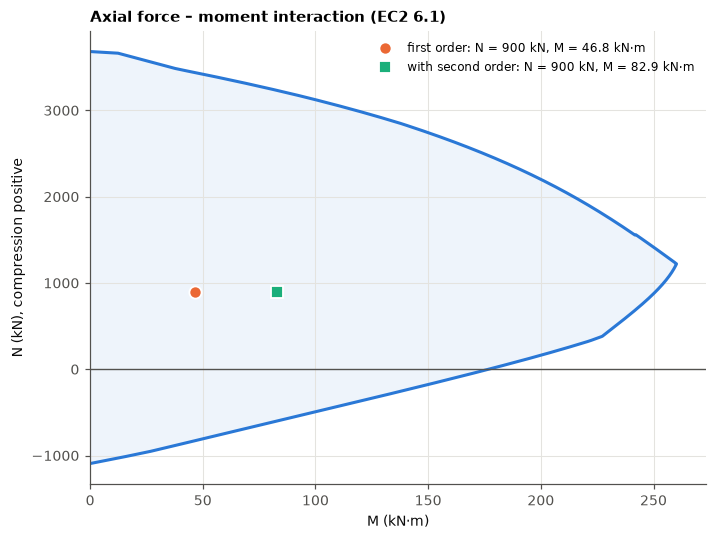

### Links

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 9.5.3(1) | $\phi_{link,min} = \max\left\{6;\; \dfrac{20}{4}\right\}$<br>$\quad = \max\left\{6;\; \dfrac{20}{4}\right\}$ | $\mathbf{\phi_{link,min} = 6}$ mm |
| EC2 9.5.3(1) | **Check:** link diameter<br>$\phi_{link} = 8 \ge \phi_{link,min} = 6$ mm | ✅ **PASS**<br>ratio 0.75 |
| EC2 9.5.3(3), NA | min(20 φ_min, smaller side, 400): $s_{cl,max}$ | $s_{cl,max} = 400$ mm |
|  | Link spacing: $s_{link}$ | $s_{link} = 325$ mm |
| EC2 9.5.3(3) | **Check:** link spacing<br>$s_{link} = 325 \le s_{cl,max} = 400$ mm | ✅ **PASS**<br>ratio 0.81 |
| EC2 9.5.3(4) | Within 400 mm above/below a beam or slab, and at laps of bars > 14 mm<br>$s_{cl,red} = 0.6\,s_{cl,max}$<br>$\quad = 0.6\times 400$ | $\mathbf{s_{cl,red} = 240}$ mm |
|  | **PROVIDE: H8 links @ 325 mm; @ 225 mm near beams, slabs and laps** | 🟦 **H8 links @ 325 mm; @ 225 mm near beams, slabs and laps** |
|  | Distance from an intermediate bar to the restrained corner bar (centres): $s_{face}$ | $s_{face} = 157$ mm |
| EC2 9.5.3(6) | 157 mm > 150 mm, so the middle bars are themselves restrained by cross-ties. |  |
|  | **PROVIDE: H8 cross-ties to the middle bars, both directions, at every link** | 🟦 **H8 cross-ties to the middle bars, both directions, at every link** |
| EC2 9.5.3(6) | **Check:** every bar restrained (cross-ties provided) | ✅ **PASS** |


### Fire resistance (tabulated method B)

| Reference | Calculation | Output |
|:--|:--|:--|
| EN 1992-1-2 5.3.3(3) Note 1 | $N_{0,fi} = 0.7\,N_{Ed}$<br>$\quad = 0.7\times 900$ | $\mathbf{N_{0,fi} = 630}$ kN |
| EN 1992-1-2 Exp. (5.8a) | $n_{fi} = \dfrac{N_{0,fi}\times 1000}{0.7\,\left(A_{c}\,f_{cd} + A_{s}\,f_{yd}\right)}$<br>$\quad = \dfrac{630\times 1000}{0.7\times \left(160000\times 17 + 2513.3\times 434.8\right)}$ | $\mathbf{n_{fi} = 0.236}$ |
| EN 1992-1-2 5.3.3(2) | $\omega = \dfrac{A_{s}\,f_{yd}}{A_{c}\,f_{cd}}$<br>$\quad = \dfrac{2513.3\times 434.8}{160000\times 17}$ | $\mathbf{\omega = 0.402}$ |
| EN 1992-1-2 Table 5.2b | **Check:** fire – tabulated row ω = 0.1 is conservative<br>$\omega = 0.402 \ge 0.1$  | ✅ **PASS**<br>ratio 0.25 |
|  | First-order eccentricity: $e_{fi}$ | $e_{fi} = 51.96$ mm |
| EN 1992-1-2 5.3.3(2) | min(0.25b, 100): $e_{max}$ | $e_{max} = 100$ mm |
| EN 1992-1-2 5.3.3(2) | **Check:** fire – method B eccentricity limit<br>$e_{fi} = 51.96 \le e_{max} = 100$ mm | ✅ **PASS**<br>ratio 0.52 |
| EN 1992-1-2 5.3.3(3) Note 2 | 0.5 × storey height: $l_{0,fi}$ | $l_{0,fi} = 3.25$ m |
| EN 1992-1-2 Exp. (5.8c) | $\lambda_{fi} = \dfrac{l_{0,fi}\times 1000}{i}$<br>$\quad = \dfrac{3.25\times 1000}{115.5}$ | $\mathbf{\lambda_{fi} = 28.15}$ |
| EN 1992-1-2 5.3.3(2) | **Check:** fire – method B slenderness limit<br>$\lambda_{fi} = 28.15 \le 30$  | ✅ **PASS**<br>ratio 0.94 |
| EN 1992-1-2 Table 5.2b | R 60, column n = 0.3, tabulated width 300 mm: $a_{req}$ | $a_{req} = 25$ mm |
|  | Axis distance: $a_{prov}$ | $a_{prov} = 43$ mm |
| EN 1992-1-2 5.3.3 | **Check:** fire – axis distance<br>$a_{prov} = 43 \ge a_{req} = 25$ mm | ✅ **PASS**<br>ratio 0.58 |


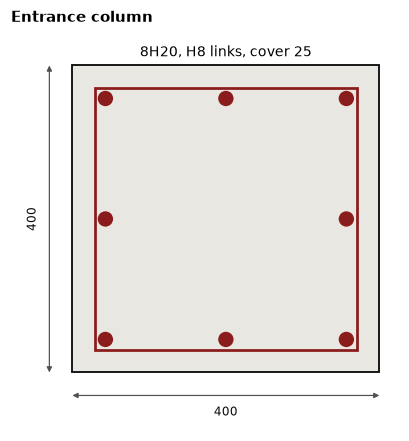

### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| nominal cover | EC2 4.4.1 | 1.00 | ✅ PASS |
| minimum steel | EC2 9.5.2(2) | 0.13 | ✅ PASS |
| maximum steel | EC2 9.5.2(3) | 0.39 | ✅ PASS |
| bending + axial with second-order effects | EC2 5.8.8, 6.1 | 0.33 | ✅ PASS |
| link diameter | EC2 9.5.3(1) | 0.75 | ✅ PASS |
| link spacing | EC2 9.5.3(3) | 0.81 | ✅ PASS |
| every bar restrained (cross-ties provided) | EC2 9.5.3(6) | – | ✅ PASS |
| fire – tabulated row ω = 0.1 is conservative | EN 1992-1-2 Table 5.2b | 0.25 | ✅ PASS |
| fire – method B eccentricity limit | EN 1992-1-2 5.3.3(2) | 0.52 | ✅ PASS |
| fire – method B slenderness limit | EN 1992-1-2 5.3.3(2) | 0.94 | ✅ PASS |
| fire – axis distance | EN 1992-1-2 5.3.3 | 0.58 | ✅ PASS |

**All checks pass.**

In [5]:
s.let("i_s", math.sqrt(6 * (h / 2 - s["d_c"]) ** 2 / 8), "mm", "Radius of gyration of the bars (6 of 8 bars at ± (h/2 − d_c))", "EC2 5.8.8.3(2)"); s.calc("d", "h/2 + i_s", "mm", "EC2 5.8.8.3(2)")
C.creep(s, b, h, RH, t0); s.show("Creep coefficient")
C.second_order(s, s["d"], ratio); s.show("Nominal curvature")
s.calc("M_Ed", "max(M_02, M_0e + M_2, M_01 + 0.5*M_2, M_min)", "kN·m", "EC2 5.8.8.2(1), 6.1(4); BS 8110-1 3.8.3.2", "Design moment. The M₀₁ + 0.5M₂ term is from BS 8110-1 3.8.3.2 c), not EC2")
cur = C.interaction(b, h, C.perimeter_layers(3, 3, phi, b, h, s["d_c"]), s["f_cd"], s["f_yd"]); s.let("M_Rd", C.MRd(cur, N), "kN·m", "Resistance at N_Ed", "EC2 6.1"); s.check("M_Ed", "<=", "M_Rd", "bending + axial with second-order effects", "EC2 5.8.8, 6.1"); s.show("Section check")
P.interaction_plot(cur, [("first order", N, s["M_02"]), ("with second order", N, s["M_Ed"])])
C.links(s, phi, phi, b, h, link, s_link, 3, 3, c, ties=True); s.show("Links")
D.fire_column_b(s, R, b, s["d_c"], N, s["A_s"], b * h, 0.5 * l, h / math.sqrt(12), s["M_02"] / N * 1e3)
P.column_section(b, h, c, link, (3, 3), phi, "Entrance column"); s.summary()

## Influence of column height

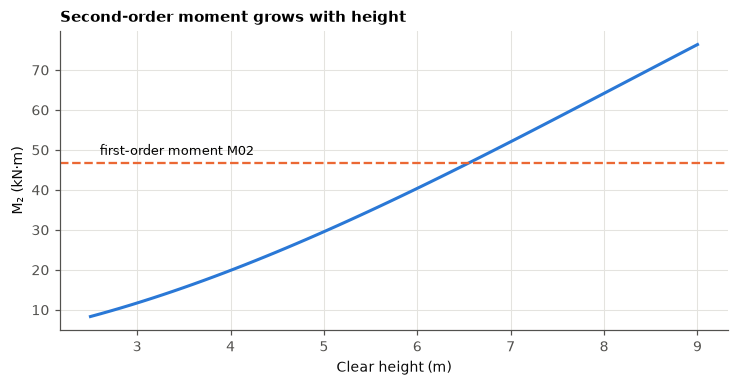

In [6]:
hs = np.linspace(2.5, 9, 60); M2 = []
for q in hs:
    l0 = 0.5 * q * math.sqrt((1 + k1 / (.45 + k1)) * (1 + k2 / (.45 + k2))) * 1000; lam = l0 / s["i"]; Kp = max(1 + (0.35 + s["f_ck"] / 200 - lam / 150) * s["phi_ef"], 1); M2.append(N * s["K_r"] * Kp * s["curv0"] * l0**2 / 10 / 1000)
f, ax = plt.subplots(figsize=(6.6, 3.4)); ax.plot(hs, M2, color=P.BLUE, lw=2); ax.axhline(s["M_02"], color=P.ORANGE, ls="--"); ax.text(2.6, s["M_02"] + 2, "first-order moment M02", fontsize=8.5); ax.set_xlabel("Clear height (m)"); ax.set_ylabel("M₂ (kN·m)"); ax.set_title("Second-order moment grows with height"); plt.show()